# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas de arquitectura, entrenamiento, evaluación y predicción ya están completadas.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


**Estudiante:** Jaime Andrés Jaramillo Ramírez.


### Antes de empezar

Ejecuto las celdas en orden. En Google Colab puedo usar el entorno estándar con TensorFlow y Keras 3. Si faltan librerías, ejecuto en una celda `%pip install -q "keras>=3,<4" tensorflow scikit-learn matplotlib` y reinicio el kernel antes de comenzar. La primera carga necesita internet para descargar el dataset.

Conservo la división y los parámetros del enunciado. El taller usa el conjunto de prueba como validación durante `fit`: sus imágenes no actualizan los pesos, pero sus métricas sí se observan. Por eso, si ajustara hiperparámetros mirando esas curvas, necesitaría separar una validación y reservar otro test para una evaluación final independiente.

---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** Cada imagen queda con **64 × 64 = 4096 valores**. Flatten cambia la forma del arreglo, pero no agrega ni quita píxeles.





---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


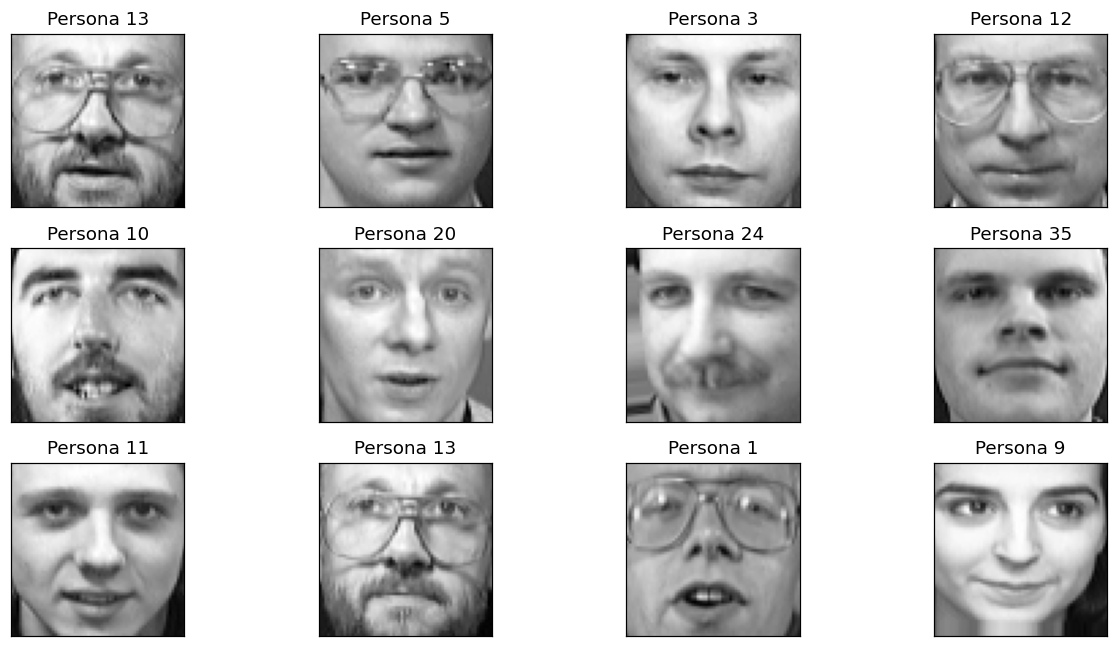

In [4]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [5]:
# Primero aplanamos la imagen y después calculamos una puntuación por persona.
model = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40)
])
model.summary()


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 264,808 (1.01 MB)
 Trainable params: 264,808 (1.01 MB)
 Non-trainable params: 0 (0.00 B)


In [6]:
# Validación del ejercicio 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Con Flatten convierto cada imagen en un vector, para que la capa Dense combine todos sus píxeles y produzca una clasificación por imagen. Sin aplanarla, Dense actuaría sobre la última dimensión y no haría la operación que pide esta arquitectura.



### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque tenemos 40 personas. Cada neurona entrega el logit correspondiente a una identidad, desde la clase 0 hasta la 39.



### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** ReLU devuelve max(0, x): deja pasar los valores positivos y convierte los negativos en cero. Así la red puede aprender relaciones no lineales; sin una activación no lineal, varias capas densas seguirían siendo equivalentes a una transformación afín.





---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [7]:
lr_rate = 0.001
# Las etiquetas son enteros y la salida todavía no tiene Softmax.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)
print("✓ Modelo configurado.")


✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque la última capa entrega puntuaciones sin normalizar, llamadas logits. Con from_logits=True, la pérdida las procesa de forma numéricamente estable. Uso SparseCategoricalCrossentropy porque las etiquetas son enteros, no vectores one-hot.





---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [8]:
epochs = 30
batch_size = 32
# Solo X_train y y_train se usan para actualizar los pesos.
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)


Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.0156 - loss: 3.9050 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0188 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0219 - loss: 3.6890 - val_accuracy: 0.0250 - val_loss: 3.6889
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0250 - loss: 3.6890 - val_accuracy: 0.0250 - v

### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una época es una pasada completa por las 320 imágenes de entrenamiento. En 30 épocas la red vuelve a recorrer ese conjunto 30 veces, actualizando sus pesos por lotes.



### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** La red procesa grupos de 32 imágenes para calcular la pérdida y actualizar los pesos. Como hay 320 imágenes, hace 10 actualizaciones por época.





---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


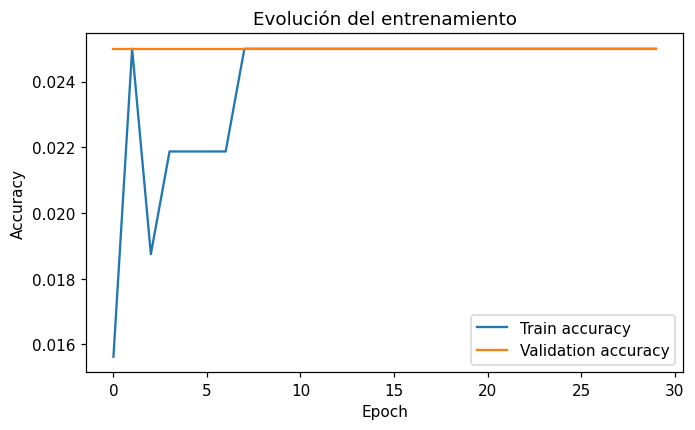

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gráfica:

- ¿El accuracy de entrenamiento sigue aumentando?
- ¿El accuracy de validación se comporta igual?
- ¿Observas evidencia de **overfitting**?

**Respuesta:** En esta ejecución, entrenamiento terminó en **2,5 %** y validación permaneció en **2,5 %**. No veo sobreajuste: ambos resultados son muy bajos y están al nivel del azar entre 40 personas. El problema fue que el modelo no aprendió a distinguir las caras. En la revisión adicional comprobé que las 64 neuronas ocultas quedaron inactivas; debajo muestro los valores de las curvas.





In [10]:
from IPython.display import display, Markdown

# Miro los valores reales de las curvas antes de sacar una conclusión.
def comentar_curvas(history):
    h = history.history
    train = np.asarray(h["accuracy"])
    val = np.asarray(h["val_accuracy"])
    loss_val = np.asarray(h["val_loss"])
    ventana = min(5, len(train))
    aumento_train = train[-1] - train[-ventana]
    aumento_val = val[-1] - val[-ventana]
    brecha = train[-1] - val[-1]
    mejor = int(np.argmax(val)) + 1
    texto = (
        f"El accuracy de entrenamiento pasó de **{train[0]:.2%}** a **{train[-1]:.2%}**, "
        f"y el de validación de **{val[0]:.2%}** a **{val[-1]:.2%}**. "
        f"En las últimas {ventana} épocas, los cambios fueron "
        f"**{100*aumento_train:+.2f}** y **{100*aumento_val:+.2f} puntos porcentuales**, respectivamente. "
        f"La brecha final fue de **{100*brecha:.2f} puntos**, y el mejor accuracy de validación "
        f"se alcanzó en la época **{mejor}** ({val.max():.2%}). "
        f"La pérdida de validación terminó en **{loss_val[-1]:.4f}**, "
        f"frente a un mínimo de **{loss_val.min():.4f}**. "
    )
    if aumento_train > 0 and aumento_val <= 0 and brecha > 0:
        texto += "Veo señales de sobreajuste: al final mejora entrenamiento, pero validación no mejora."
    elif brecha > 0.05:
        texto += "La diferencia a favor de entrenamiento sugiere sobreajuste, aunque también reviso la evolución de las curvas y no solo el último valor."
    elif aumento_train > 0 and aumento_val > 0:
        texto += "Ambos conjuntos mejoran en el tramo final y no veo una separación grande al terminar. No tengo una señal clara de sobreajuste en este entrenamiento."
    else:
        texto += "Con estos valores no veo evidencia clara de sobreajuste. Las fluctuaciones por sí solas no son suficientes para afirmarlo."
    return texto

comentario_curvas = comentar_curvas(history)
display(Markdown(comentario_curvas))

El accuracy de entrenamiento pasó de **1.56%** a **2.50%**, y el de validación de **2.50%** a **2.50%**. En las últimas 5 épocas, los cambios fueron **+0.00** y **+0.00 puntos porcentuales**, respectivamente. La brecha final fue de **0.00 puntos**, y el mejor accuracy de validación se alcanzó en la época **1** (2.50%). La pérdida de validación terminó en **3.6889**, frente a un mínimo de **3.6889**. Con estos valores no veo evidencia clara de sobreajuste. Las fluctuaciones por sí solas no son suficientes para afirmarlo.

---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [11]:
# Ahora medimos el desempeño sin actualizar los pesos.
test_loss, test_accuracy = model.evaluate(
    X_test, y_test,
    batch_size=batch_size,
    verbose=0
)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 3.6889
Test accuracy : 0.0250
Accuracy (%)  : 2.50%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** Es una cantidad pequeña: la red tiene **264.808 parámetros** y solo **320 imágenes**, es decir, ocho por persona. Puede aprender detalles particulares de esas fotos y generalizar peor a otras. Tener muchos parámetros no demuestra por sí solo sobreajuste, pero con tan pocos ejemplos hay que revisar las curvas con cuidado.





---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


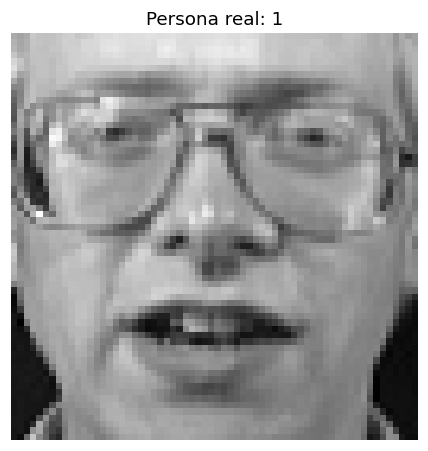

Shape de logits: (1, 40)

Primeros 10 logits:
[ 0.00078378 -0.00700769  0.00334249 -0.00296516 -0.00047903 -0.00141983
 -0.00902546  0.00582534 -0.00014707  0.00095134]


In [12]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [13]:
# Softmax convierte las puntuaciones en probabilidades.
probabilities = keras.ops.softmax(logits, axis=-1)
# Me quedo con la clase que tiene la probabilidad más alta.
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])
assert np.allclose(keras.ops.convert_to_numpy(probabilities).sum(axis=1), 1.0)
print("Clase real     :", true_class)
print("Clase predicha :", prediction)


Clase real     : 1
Clase predicha : 10


In [14]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona 10: 0.0252
Persona 17: 0.0252
Persona  7: 0.0251
Persona 26: 0.0251
Persona 19: 0.0251

Suma de probabilidades: 1.0


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Softmax calcula exp(z_i) dividido entre la suma de exp(z_j) de todas las clases. Al sumar esas fracciones obtengo 1. En el computador puede aparecer una diferencia muy pequeña por el redondeo de los números flotantes.





---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


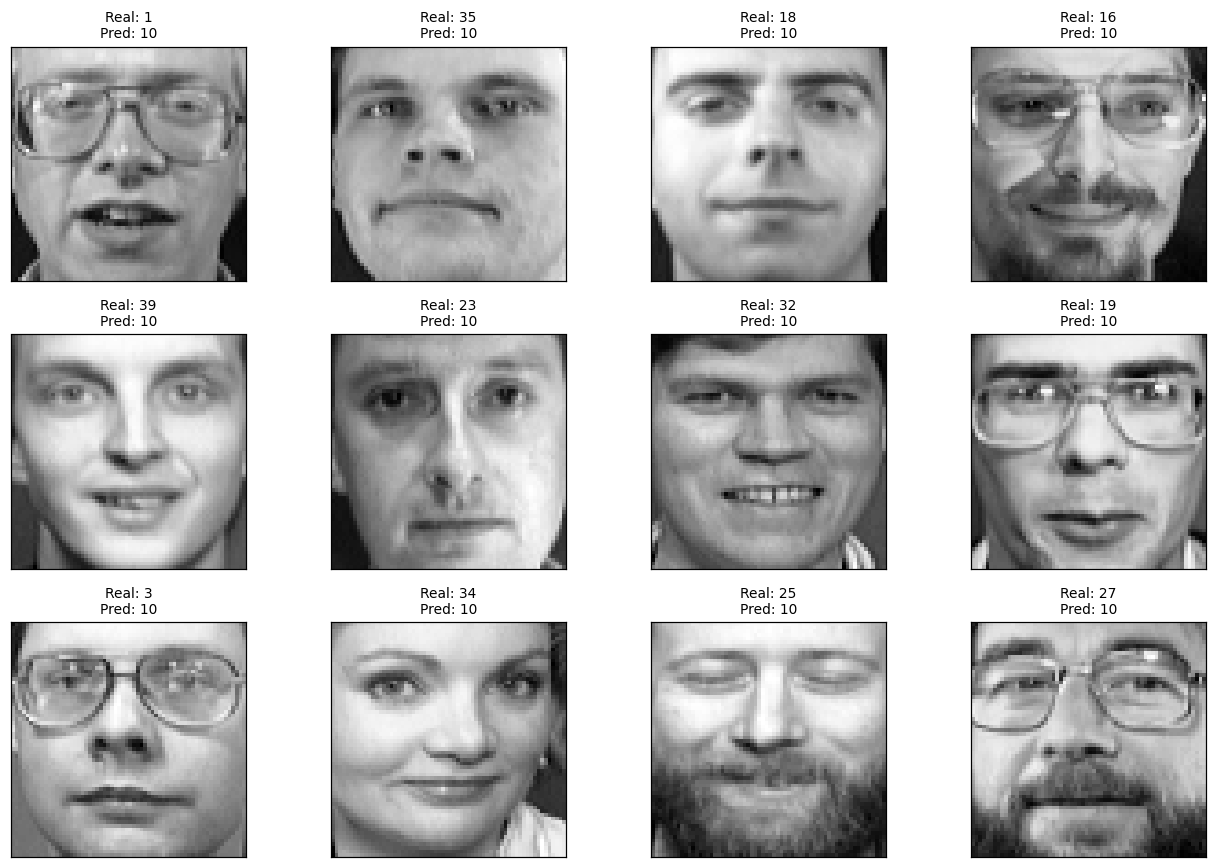

In [15]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** Con la configuración solicitada obtuve **2,5 % de accuracy**, es decir, **2 aciertos de 80 imágenes de prueba**. El experimento adicional con menor tasa de aprendizaje obtuvo **21,25 %**, pero mantengo ambos resultados separados.



### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** No observé una brecha que indique sobreajuste: entrenamiento y validación terminaron en 2,5 %. Sin embargo, eso no indica un buen modelo, porque no aprendió a clasificar. La gráfica casi plana y las neuronas ReLU inactivas respaldan esa conclusión.



### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** La red tiene mucha capacidad para ajustar los ejemplos, incluso detalles que no ayudan a reconocer nuevas fotos. Por eso puede memorizar entrenamiento. Consideraría más datos, regularización o una red más pequeña, y comprobaría el efecto con validación.



### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números.

¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** No se borran los valores de los píxeles y podría reconstruir la imagen si conozco su forma. Lo que deja de quedar explícito es la estructura bidimensional: qué píxeles son vecinos y cómo se organizan los patrones locales. La red densa no aprovecha esa estructura por diseño.



### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** Una CNN, porque sus filtros recorren regiones de la imagen y aprenden patrones locales como bordes y texturas. Además, comparten pesos entre posiciones. Esto suele aprovechar mejor la estructura espacial, aunque el resultado debe comprobarse entrenando y evaluando el modelo.



---

## Para pensar

Nuestra red recibe:

```text
64 × 64
   ↓
Flatten
   ↓
4096 números
   ↓
Dense
```

Pero una imagen tiene una estructura espacial:

- píxeles cercanos están relacionados,
- existen bordes,
- existen formas,
- existen patrones locales.

Una red fully-connected no incorpora explícitamente esa estructura.

Esto motiva una arquitectura diseñada específicamente para imágenes:

> **Convolutional Neural Networks (CNNs)**


In [16]:
# Dejo el resultado conectado al entrenamiento para no escribir un número inventado.
all_logits = model.predict(X_test, batch_size=batch_size, verbose=0)
all_predictions = np.argmax(all_logits, axis=1)
aciertos = int(np.sum(all_predictions == y_test))
assert np.isclose(test_accuracy, aciertos / len(y_test), atol=1e-6)
display(Markdown(
    f"**Mi resultado final:** obtuve un accuracy de **{test_accuracy:.2%}** "
    f"({aciertos} aciertos de {len(y_test)} imágenes), con pérdida **{test_loss:.4f}**.\n\n"
    + comentario_curvas
))

**Mi resultado final:** obtuve un accuracy de **2.50%** (2 aciertos de 80 imágenes), con pérdida **3.6889**.

El accuracy de entrenamiento pasó de **1.56%** a **2.50%**, y el de validación de **2.50%** a **2.50%**. En las últimas 5 épocas, los cambios fueron **+0.00** y **+0.00 puntos porcentuales**, respectivamente. La brecha final fue de **0.00 puntos**, y el mejor accuracy de validación se alcanzó en la época **1** (2.50%). La pérdida de validación terminó en **3.6889**, frente a un mínimo de **3.6889**. Con estos valores no veo evidencia clara de sobreajuste. Las fluctuaciones por sí solas no son suficientes para afirmarlo.

---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.


### Revisión del aprendizaje

Un accuracy cercano a **1/40 = 2,5 %** está al nivel de una elección al azar entre las 40 personas. Si entrenamiento y validación quedan en ese nivel, no significa que el modelo generalice bien: significa que no logró aprender a distinguir las identidades. Para investigar ese caso reviso las activaciones de ReLU y pruebo una tasa de aprendizaje menor, sin reemplazar el modelo pedido en el taller.

El modelo principal conserva **Adam con 0,001 y 30 épocas**. El experimento de abajo es adicional y usa **0,0001**, con la misma arquitectura y 30 épocas. Como ya observé los resultados de prueba, esta comparación es exploratoria; no la trato como una nueva evaluación independiente.

In [17]:
# Reviso si las neuronas ocultas todavía se activan con las imágenes.
modelo_oculto = keras.Model(inputs=model.inputs, outputs=model.layers[1].output)
activaciones = keras.ops.convert_to_numpy(modelo_oculto(X_train, training=False))
neuronas_inactivas = int(np.sum(np.all(activaciones == 0, axis=0)))
print(f"Neuronas sin activarse en entrenamiento: {neuronas_inactivas} de 64")
print("Número de identidades que predijo el modelo:", len(np.unique(all_predictions)))

# Pruebo pasos más pequeños con Adam y mantengo el modelo original por separado.
keras.utils.set_random_seed(SEED)
model_ajustado = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40),
])
model_ajustado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)
history_ajustado = model_ajustado.fit(
    X_train, y_train, epochs=30, batch_size=32,
    validation_data=(X_test, y_test), shuffle=True, verbose=2,
)
loss_ajustado, accuracy_ajustado = model_ajustado.evaluate(X_test, y_test, verbose=0)
display(Markdown(
    f"Con la configuración del taller obtuve **{test_accuracy:.2%}**; "
    f"con learning_rate=0,0001 obtuve **{accuracy_ajustado:.2%}**. "
    f"La diferencia fue de **{100*(accuracy_ajustado-test_accuracy):+.2f} puntos porcentuales**. "
    f"En el modelo original encontré **{neuronas_inactivas} neuronas ocultas inactivas** "
    "en todas las imágenes de entrenamiento. Esta revisión ayuda a distinguir un problema "
    "de aprendizaje de un problema de sobreajuste."
))

Neuronas sin activarse en entrenamiento: 64 de 64
Número de identidades que predijo el modelo: 1
Epoch 1/30
10/10 - 1s - 114ms/step - accuracy: 0.0125 - loss: 3.7645 - val_accuracy: 0.0250 - val_loss: 3.6695
Epoch 2/30
10/10 - 0s - 17ms/step - accuracy: 0.0375 - loss: 3.6543 - val_accuracy: 0.0500 - val_loss: 3.6482
Epoch 3/30
10/10 - 0s - 14ms/step - accuracy: 0.0594 - loss: 3.6381 - val_accuracy: 0.0375 - val_loss: 3.6347
Epoch 4/30
10/10 - 0s - 16ms/step - accuracy: 0.0312 - loss: 3.6249 - val_accuracy: 0.0375 - val_loss: 3.6228
Epoch 5/30
10/10 - 0s - 13ms/step - accuracy: 0.0500 - loss: 3.6078 - val_accuracy: 0.0625 - val_loss: 3.6088
Epoch 6/30
10/10 - 0s - 14ms/step - accuracy: 0.0594 - loss: 3.5940 - val_accuracy: 0.0375 - val_loss: 3.5990
Epoch 7/30
10/10 - 0s - 15ms/step - accuracy: 0.0750 - loss: 3.5776 - val_accuracy: 0.0875 - val_loss: 3.5855
Epoch 8/30
10/10 - 0s - 14ms/step - accuracy: 0.0812 - loss: 3.5651 - val_accuracy: 0.0875 - val_loss: 3.5756
Epoch 9/30
10/10 - 0s 

/root/.local/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(320, 64, 64))
  warnings.warn(msg)


Con la configuración del taller obtuve **2.50%**; con learning_rate=0,0001 obtuve **21.25%**. La diferencia fue de **+18.75 puntos porcentuales**. En el modelo original encontré **64 neuronas ocultas inactivas** en todas las imágenes de entrenamiento. Esta revisión ayuda a distinguir un problema de aprendizaje de un problema de sobreajuste.

### Cierre

Completé la arquitectura, la configuración de la pérdida y el optimizador, el entrenamiento, la evaluación y las predicciones. Los comentarios y las conclusiones numéricas se calculan a partir de la ejecución para que coincidan con las gráficas. La semilla ayuda a repetir el experimento, aunque pueden aparecer diferencias entre equipos y versiones.

Referencia de las funciones: [documentación de Keras 3](https://keras.io/api/).